# End-to-end YOLO11n shoe-brand classification

Train, tune, evaluate, analyze, and export a `yolo11n-cls.pt` model for Adidas, Converse, and Nike. Run the cells sequentially after completing dataset setup, stratified splitting, preprocessing, and EDA.

## 0. Install dependencies into the active kernel

This cell installs packages through the exact Python executable used by this notebook. Restart the kernel if Jupyter reports that newly installed native packages cannot be loaded, then continue from the import cell.

In [1]:
import subprocess
import sys

REQUIRED_PACKAGES = [
    "matplotlib",
    "numpy",
    "pandas",
    "Pillow",
    "PyYAML",
    "scikit-learn",
    "seaborn",
    "torch",
    "torchvision",
    "ultralytics==8.4.213",
]
subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "--disable-pip-version-check",
    *REQUIRED_PACKAGES,
])
print(f"Dependencies installed for kernel: {sys.executable}")

Dependencies installed for kernel: c:\Program Files\Python311\python.exe


## 1. Imports and experiment configuration

In [2]:
import json
import os
import platform
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import yaml
from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from ultralytics import YOLO, __version__ as ultralytics_version

DATASET_ROOT = Path("../datasets/shoe_brands_preprocessed").resolve()
RUNS_ROOT = Path("../runs/training").resolve()
EVALUATION_ROOT = RUNS_ROOT / "evaluation"
PROJECT_ROOT = Path("../..").resolve()
MODEL_ROOT = PROJECT_ROOT / "model"
MODEL_CHECKPOINT = "yolo11n-cls.pt"
EXPECTED_CLASSES = ["adidas", "converse", "nike"]
EXPECTED_COUNTS = {"train": 193, "val": 55, "test": 27}
IMAGE_SIZE = 224
BATCH_SIZE = 32
WORKERS = min(8, os.cpu_count() or 1)
SEED = 37
BASELINE_EPOCHS = 30
TUNING_ITERATIONS = 20
TUNING_EPOCHS = 20
FINAL_EPOCHS = 100
PATIENCE = 20
RUN_TUNING = True
EXPORT_ONNX = True

## 2. Runtime, device, and reproducibility

In [3]:
def select_device() -> str | int:
    if torch.cuda.is_available():
        return 0
    if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        return "mps"
    return "cpu"


DEVICE = select_device()
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print(f"Python executable: {os.sys.executable}")
print(f"Python: {platform.python_version()}")
print(f"NumPy: {np.__version__}")
print(f"pandas: {pd.__version__}")
print(f"seaborn: {sns.__version__}")
print(f"PyTorch: {torch.__version__}")
print(f"Ultralytics: {ultralytics_version}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Python executable: c:\Program Files\Python311\python.exe
Python: 3.11.9
NumPy: 2.4.4
pandas: 3.1.1
seaborn: 0.13.2
PyTorch: 2.15.0+cpu
Ultralytics: 8.4.213
CUDA available: False
Device: cpu


## 3. Dataset validation

In [4]:
SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
dataset_counts = {}
for split_name, expected_count in EXPECTED_COUNTS.items():
    split_path = DATASET_ROOT / split_name
    if not split_path.is_dir():
        raise FileNotFoundError(f"Missing dataset split: {split_path}")

    actual_classes = sorted(path.name for path in split_path.iterdir() if path.is_dir())
    if actual_classes != EXPECTED_CLASSES:
        raise ValueError(f"Unexpected classes in {split_name}: {actual_classes}")

    dataset_counts[split_name] = {}
    for class_name in EXPECTED_CLASSES:
        image_count = sum(
            1 for path in (split_path / class_name).iterdir()
            if path.is_file() and path.suffix.lower() in SUPPORTED_EXTENSIONS
        )
        dataset_counts[split_name][class_name] = image_count
        if image_count != expected_count:
            raise ValueError(
                f"Expected {expected_count} images in {split_name}/{class_name}; found {image_count}."
            )

dataset_distribution = pd.DataFrame(dataset_counts).T[EXPECTED_CLASSES]
dataset_distribution["total"] = dataset_distribution.sum(axis=1)
display(dataset_distribution)
print(f"Dataset ready: {DATASET_ROOT}")

,adidas,converse,nike,total
train,193,193,193,579
val,55,55,55,165
test,27,27,27,81


Dataset ready: C:\my-project\shoe-brand-classifier\modeling\datasets\shoe_brands_preprocessed


## 4. Baseline training

In [5]:
baseline_model = YOLO(MODEL_CHECKPOINT)
baseline_started_at = time.perf_counter()
baseline_results = baseline_model.train(
    data=str(DATASET_ROOT),
    epochs=BASELINE_EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=WORKERS,
    optimizer="AdamW",
    lr0=1e-3,
    lrf=1e-2,
    weight_decay=5e-4,
    warmup_epochs=3,
    dropout=0.1,
    hsv_h=0.01,
    hsv_s=0.3,
    hsv_v=0.2,
    degrees=8.0,
    translate=0.08,
    scale=0.2,
    fliplr=0.5,
    flipud=0.0,
    cos_lr=True,
    patience=PATIENCE,
    seed=SEED,
    deterministic=True,
    cache=False,
    save=True,
    save_period=10,
    project=str(RUNS_ROOT),
    name="baseline",
    exist_ok=True,
    plots=True,
)
baseline_duration_seconds = time.perf_counter() - baseline_started_at
BASELINE_RUN_DIR = Path(baseline_results.save_dir)
BASELINE_BEST_PATH = BASELINE_RUN_DIR / "weights" / "best.pt"
print(f"Baseline duration: {baseline_duration_seconds / 60:.2f} minutes")
print(f"Baseline best checkpoint: {BASELINE_BEST_PATH}")

Ultralytics 8.4.213  Python-3.11.9 torch-2.15.0+cpu CPU (Intel Core i5-10300H 2.50GHz)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=C:\my-project\shoe-brand-classifier\modeling\datasets\shoe_brands_preprocessed, degrees=8.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.1, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.3, hsv_v=0.2, imgsz=224, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ba

## 5. Training curves

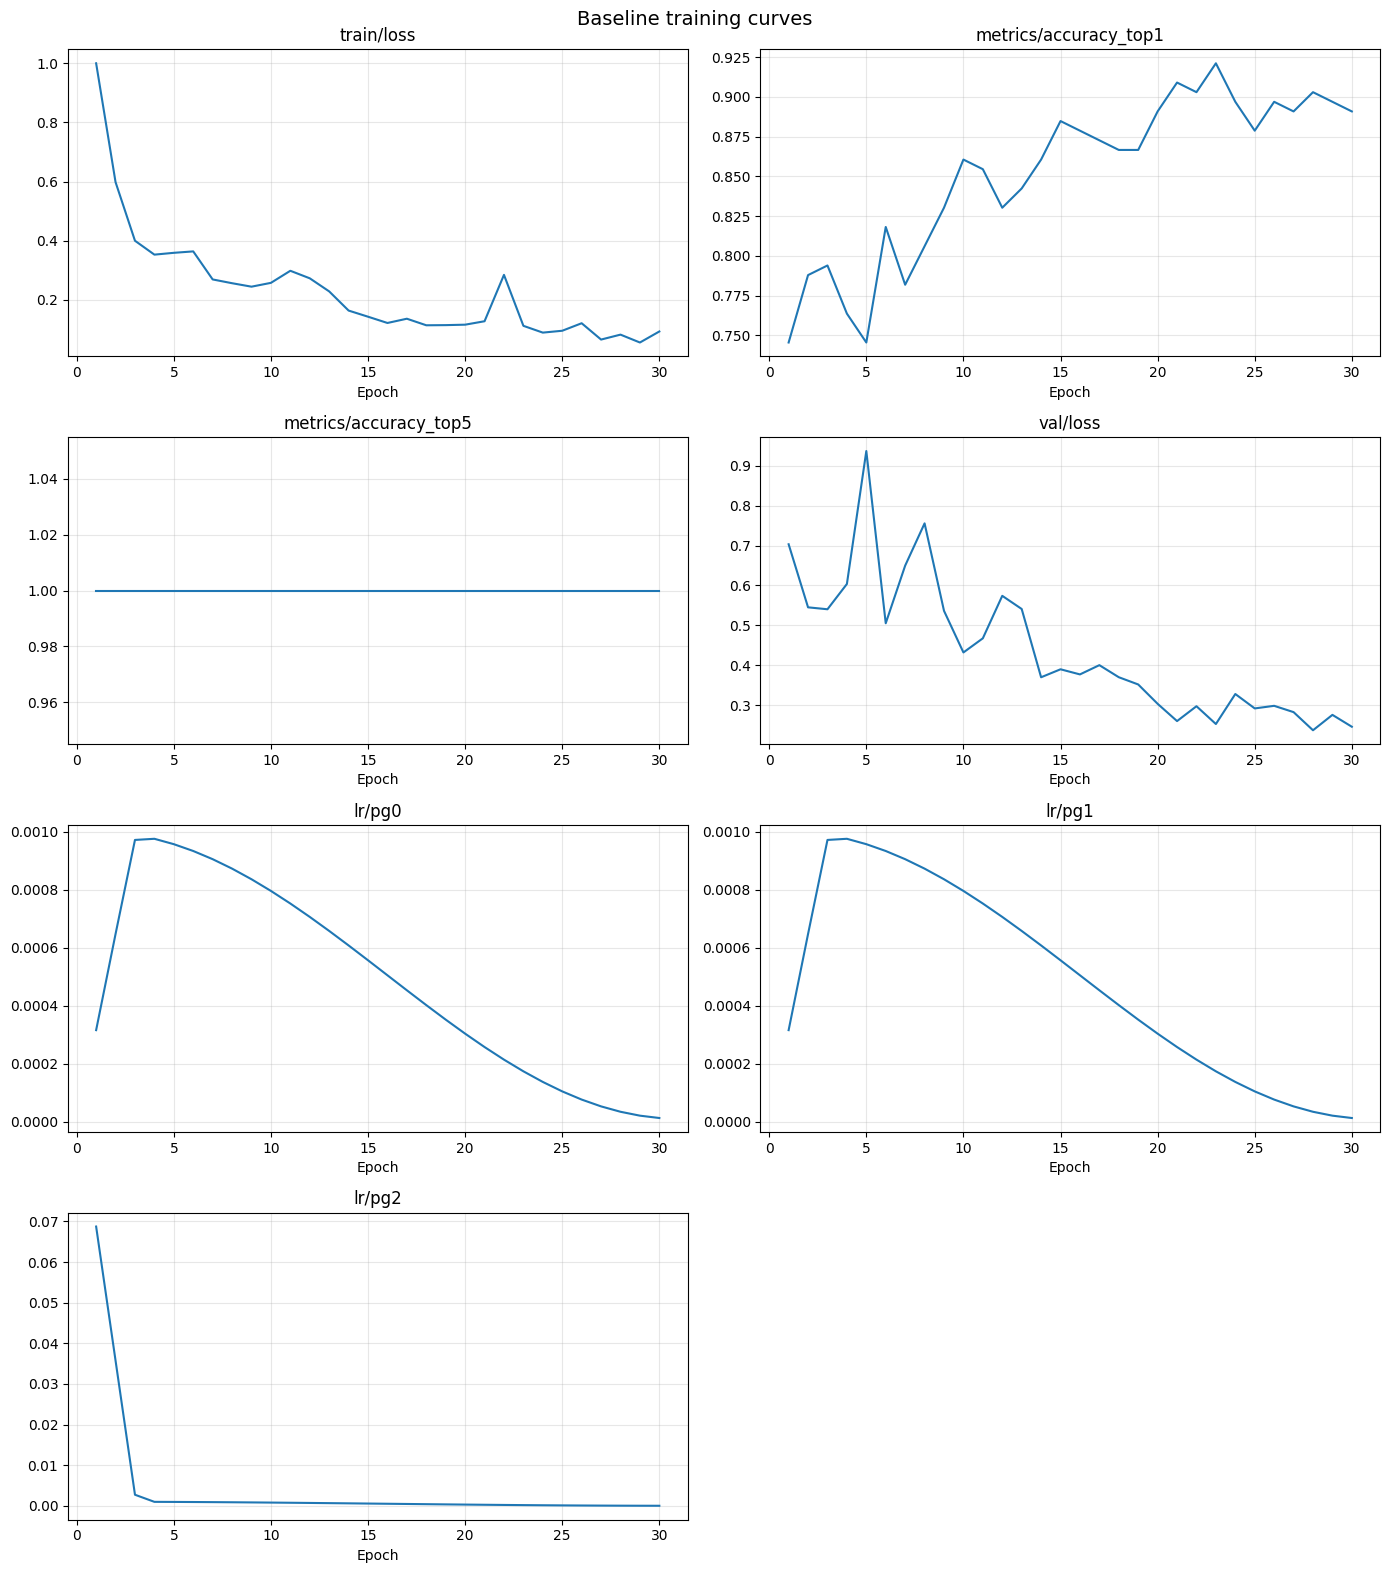

In [6]:
def load_training_history(run_directory: Path) -> pd.DataFrame:
    results_path = run_directory / "results.csv"
    if not results_path.is_file():
        raise FileNotFoundError(f"Training history not found: {results_path}")
    history = pd.read_csv(results_path)
    history.columns = history.columns.str.strip()
    return history


def plot_training_history(history: pd.DataFrame, title: str) -> None:
    metric_columns = [
        column for column in history.columns
        if any(keyword in column.lower() for keyword in ("loss", "accuracy", "top1", "top5", "lr/"))
    ]
    if not metric_columns:
        print(f"No recognized metric columns. Available columns: {list(history.columns)}")
        return

    columns = 2
    rows = int(np.ceil(len(metric_columns) / columns))
    figure, axes = plt.subplots(rows, columns, figsize=(14, 4 * rows), squeeze=False)
    for axis, metric_name in zip(axes.flat, metric_columns):
        axis.plot(history.index + 1, history[metric_name])
        axis.set_title(metric_name)
        axis.set_xlabel("Epoch")
        axis.grid(alpha=0.3)
    for axis in axes.flat[len(metric_columns):]:
        axis.axis("off")
    figure.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


baseline_history = load_training_history(BASELINE_RUN_DIR)
plot_training_history(baseline_history, "Baseline training curves")

## 6. Hyperparameter tuning

In [7]:
TUNING_PROJECT = RUNS_ROOT / "tuning"
TUNING_SPACE = {
    "lr0": (1e-5, 1e-2),
    "lrf": (0.01, 0.2),
    "momentum": (0.7, 0.98),
    "weight_decay": (0.0, 0.001),
    "warmup_epochs": (0.0, 5.0),
    "hsv_h": (0.0, 0.03),
    "hsv_s": (0.0, 0.5),
    "hsv_v": (0.0, 0.4),
    "degrees": (0.0, 12.0),
    "translate": (0.0, 0.12),
    "scale": (0.0, 0.3),
    "fliplr": (0.0, 0.5),
    "dropout": (0.0, 0.3),
}

if RUN_TUNING:
    tuning_model = YOLO(MODEL_CHECKPOINT)
    tuning_model.tune(
        data=str(DATASET_ROOT),
        epochs=TUNING_EPOCHS,
        iterations=TUNING_ITERATIONS,
        imgsz=IMAGE_SIZE,
        batch=BATCH_SIZE,
        device=DEVICE,
        workers=WORKERS,
        optimizer="AdamW",
        seed=SEED,
        deterministic=True,
        space=TUNING_SPACE,
        project=str(TUNING_PROJECT),
        name="yolo11n_cls_tune",
        plots=True,
        save=True,
        val=True,
    )

Tuner: Initialized Tuner instance with 'tune_dir=C:\my-project\shoe-brand-classifier\modeling\runs\training\tuning\yolo11n_cls_tune'
Tuner:  Learn about tuning at https://docs.ultralytics.com/guides/hyperparameter-tuning
Tuner: Starting iteration 1/20 with hyperparameters: {'lr0': 0.01, 'lrf': 0.01, 'momentum': 0.937, 'weight_decay': 0.0005, 'warmup_epochs': 3.0, 'hsv_h': 0.015, 'hsv_s': 0.5, 'hsv_v': 0.4, 'degrees': 0.0, 'translate': 0.1, 'scale': 0.3, 'fliplr': 0.5, 'dropout': 0.0}

MultiTrainer 1/1: fine-tuning on C:\my-project\shoe-brand-classifier\modeling\datasets\shoe_brands_preprocessed
MultiTrainer results saved to C:\my-project\shoe-brand-classifier\modeling\runs\training\tuning\multitrain\multitrain_results.json
MultiTrainer results saved to C:\my-project\shoe-brand-classifier\modeling\runs\training\tuning\multitrain\multitrain_results.png
Saved C:\my-project\shoe-brand-classifier\modeling\runs\training\tuning\yolo11n_cls_tune\tune_scatter_plots.png
Saved C:\my-project\shoe-

## 7. Load and review best tuning parameters

In [8]:
best_hyperparameter_files = sorted(
    TUNING_PROJECT.rglob("best_hyperparameters.yaml"),
    key=lambda path: path.stat().st_mtime,
)
if RUN_TUNING and not best_hyperparameter_files:
    raise FileNotFoundError(f"No best_hyperparameters.yaml found below {TUNING_PROJECT}")

if best_hyperparameter_files:
    BEST_HYPERPARAMETERS_PATH = best_hyperparameter_files[-1]
    with BEST_HYPERPARAMETERS_PATH.open("r", encoding="utf-8") as yaml_file:
        tuned_hyperparameters = yaml.safe_load(yaml_file) or {}
else:
    BEST_HYPERPARAMETERS_PATH = None
    tuned_hyperparameters = {}

ALLOWED_TUNED_PARAMETERS = {
    "lr0", "lrf", "momentum", "weight_decay", "warmup_epochs",
    "hsv_h", "hsv_s", "hsv_v", "degrees", "translate",
    "scale", "fliplr", "flipud", "dropout",
}
final_hyperparameters = {
    key: value for key, value in tuned_hyperparameters.items()
    if key in ALLOWED_TUNED_PARAMETERS
}

print(f"Best hyperparameters file: {BEST_HYPERPARAMETERS_PATH}")
display(pd.DataFrame.from_dict(final_hyperparameters, orient="index", columns=["value"]))

Best hyperparameters file: C:\my-project\shoe-brand-classifier\modeling\runs\training\tuning\yolo11n_cls_tune\best_hyperparameters.yaml


,value
lr0,0.00582
lrf,0.01028
momentum,0.85104
weight_decay,0.00080
warmup_epochs,3.25447
hsv_h,0.00174
hsv_s,0.50000
hsv_v,0.40000
degrees,1.22468
translate,0.12000


In [9]:
tuning_csv_files = sorted(TUNING_PROJECT.rglob("tune_results.csv"))
if tuning_csv_files:
    tuning_history = pd.read_csv(tuning_csv_files[-1])
    display(tuning_history.sort_values("fitness", ascending=False).head(10))
    if "fitness" in tuning_history.columns:
        tuning_history["fitness"].plot(figsize=(10, 4), marker="o", title="Tuning fitness by iteration")
        plt.xlabel("Iteration")
        plt.ylabel("Fitness")
        plt.grid(alpha=0.3)
        plt.show()
else:
    print("No tune_results.csv found; inspect the tuning directory manually.")

No tune_results.csv found; inspect the tuning directory manually.


## 8. Final training from fresh pretrained weights

In [10]:
final_training_arguments = {
    "data": str(DATASET_ROOT),
    "epochs": FINAL_EPOCHS,
    "imgsz": IMAGE_SIZE,
    "batch": BATCH_SIZE,
    "device": DEVICE,
    "workers": WORKERS,
    "optimizer": "AdamW",
    "patience": PATIENCE,
    "cos_lr": True,
    "seed": SEED,
    "deterministic": True,
    "cache": False,
    "save": True,
    "save_period": 10,
    "project": str(RUNS_ROOT),
    "name": "final",
    "exist_ok": True,
    "plots": True,
}
final_training_arguments.update(final_hyperparameters)

final_model = YOLO(MODEL_CHECKPOINT)
final_started_at = time.perf_counter()
final_results = final_model.train(**final_training_arguments)
final_duration_seconds = time.perf_counter() - final_started_at
FINAL_RUN_DIR = Path(final_results.save_dir)
FINAL_BEST_PATH = FINAL_RUN_DIR / "weights" / "best.pt"
if not FINAL_BEST_PATH.is_file():
    raise FileNotFoundError(f"Final best checkpoint not found: {FINAL_BEST_PATH}")

print(f"Final training duration: {final_duration_seconds / 60:.2f} minutes")
print(f"Final best checkpoint: {FINAL_BEST_PATH}")

New https://pypi.org/project/ultralytics/8.4.214 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.213  Python-3.11.9 torch-2.15.0+cpu CPU (Intel Core i5-10300H 2.50GHz)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=C:\my-project\shoe-brand-classifier\modeling\datasets\shoe_brands_preprocessed, degrees=1.22468, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.39134, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.00174, hsv_s=0.5, hsv_v=0.4, imgsz=224, iou=None, kobj=1.0, line_width=None, lr0=0.00582, lrf=0.01028, mask_r

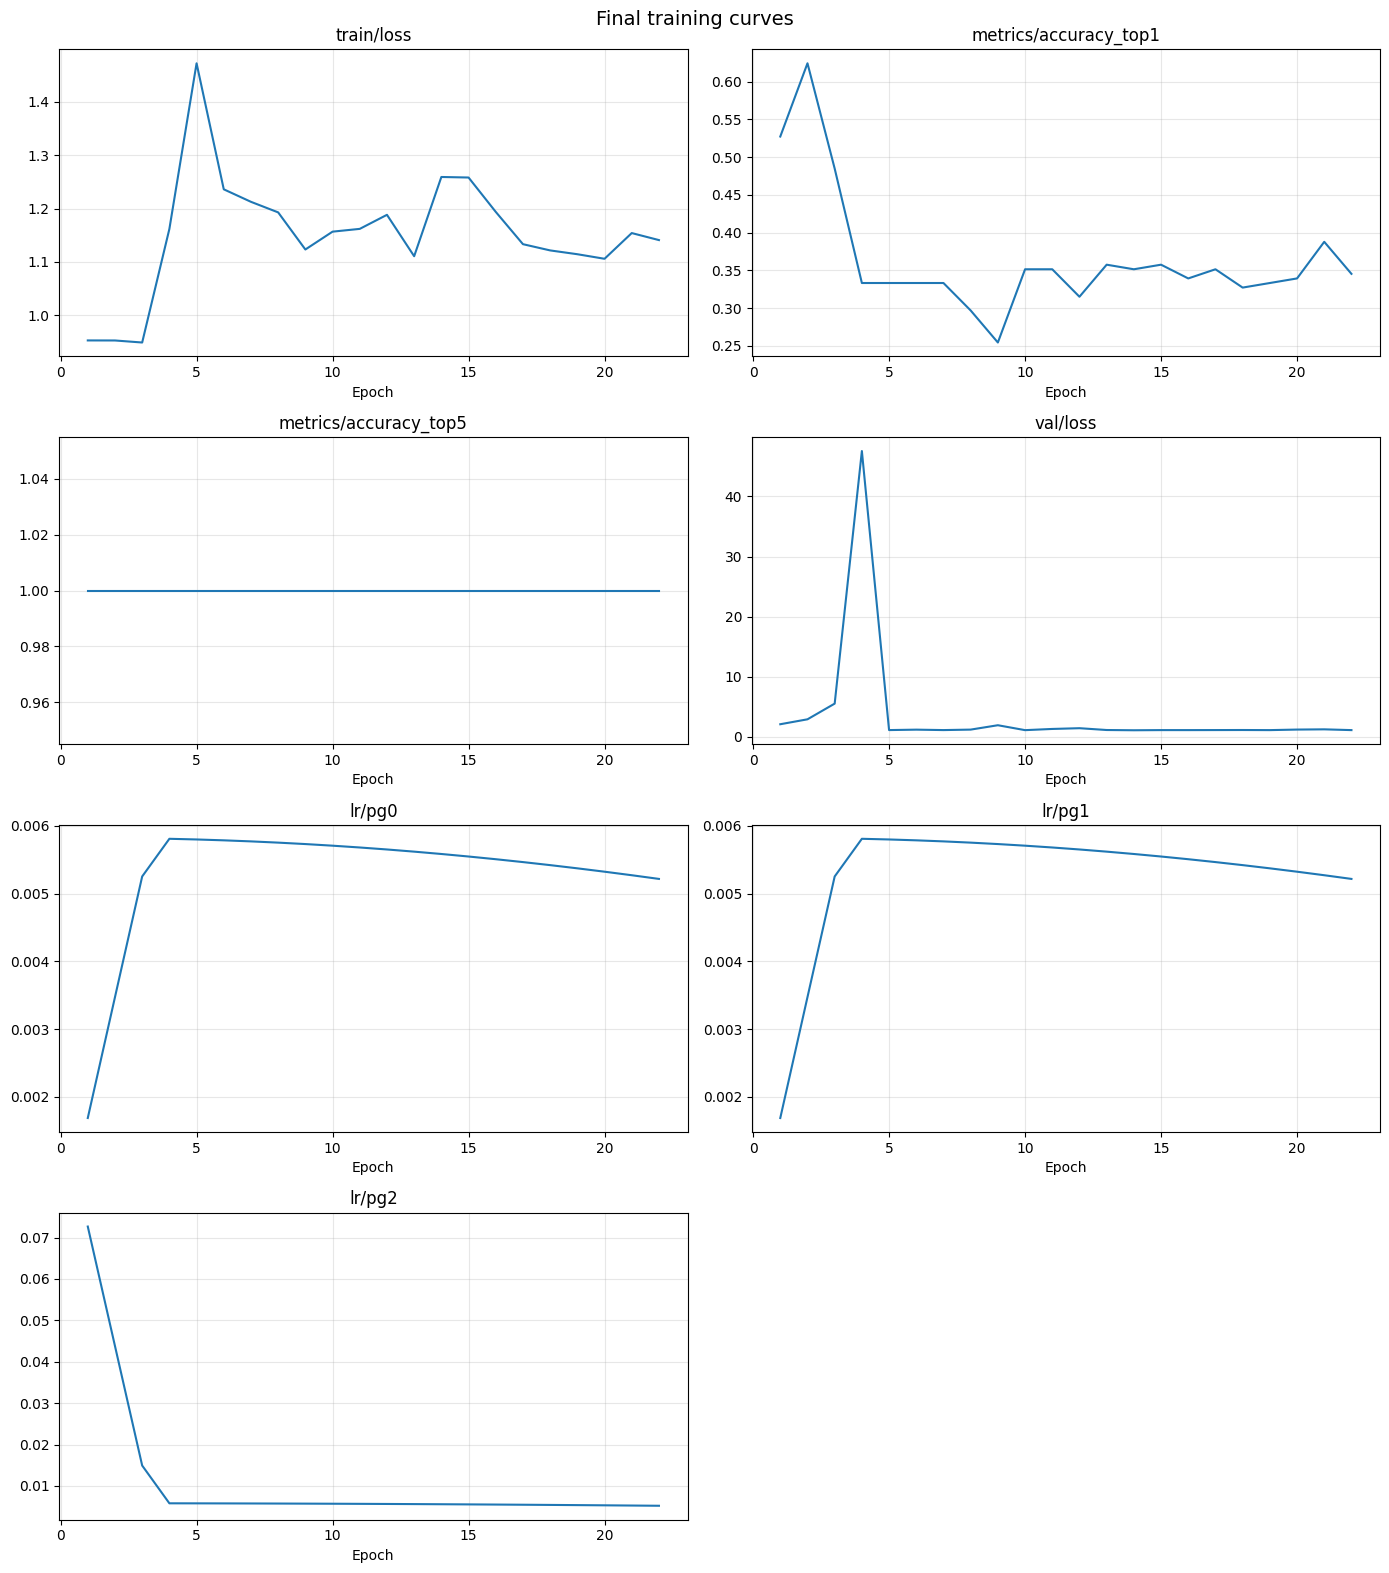

In [11]:
final_history = load_training_history(FINAL_RUN_DIR)
plot_training_history(final_history, "Final training curves")

## 9. Validation and test evaluation

In [12]:
best_model = YOLO(str(FINAL_BEST_PATH))
validation_metrics = best_model.val(
    data=str(DATASET_ROOT), split="val", imgsz=IMAGE_SIZE, batch=BATCH_SIZE, device=DEVICE, plots=True
)
test_metrics = best_model.val(
    data=str(DATASET_ROOT), split="test", imgsz=IMAGE_SIZE, batch=BATCH_SIZE, device=DEVICE, plots=True
)

evaluation_overview = pd.DataFrame({
    "split": ["validation", "test"],
    "top1_accuracy": [validation_metrics.top1, test_metrics.top1],
    "top5_accuracy": [validation_metrics.top5, test_metrics.top5],
})
display(evaluation_overview)
print(f"Validation speed: {validation_metrics.speed}")
print(f"Test speed: {test_metrics.speed}")

Ultralytics 8.4.213  Python-3.11.9 torch-2.15.0+cpu CPU (Intel Core i5-10300H 2.50GHz)
YOLO11n-cls summary (fused): 47 layers, 1,529,867 parameters, 0 gradients, 3.2 GFLOPs
train: C:\my-project\shoe-brand-classifier\modeling\datasets\shoe_brands_preprocessed\train... found 579 images in 3/3 classes  
val: C:\my-project\shoe-brand-classifier\modeling\datasets\shoe_brands_preprocessed\val... found 165 images in 3/3 classes  
test: C:\my-project\shoe-brand-classifier\modeling\datasets\shoe_brands_preprocessed\test... found 81 images in 3/3 classes  
val: Fast image access  (ping: 0.1±0.0 ms, read: 87.1±63.1 MB/s, size: 13.2 KB)
val: Scanning C:\my-project\shoe-brand-classifier\modeling\datasets\shoe_brands_preprocessed\val... 165 images, 0 corrupt: 100% ━━━━━━━━━━━━ 165/165  0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 6/6 3.1it/s 1.9s0.4s
                   all      0.624          1
Speed: 0.0ms preprocess, 7.3ms inference, 0.0ms loss, 0.0ms postprocess per image


,split,top1_accuracy,top5_accuracy
0,validation,0.624242,1.0
1,test,0.419753,1.0


Validation speed: {'preprocess': 0.0022903028311151447, 'inference': 7.331643635971528, 'loss': 4.42420555786653e-05, 'postprocess': 0.00030545510746764415}
Test speed: {'preprocess': 0.0021382713586919834, 'inference': 7.958209876511475, 'loss': 8.148138330858431e-05, 'postprocess': 0.0004493825448056062}


## 10. Test-set predictions

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import yaml
from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from ultralytics import YOLO, __version__ as ultralytics_version

dataset_candidates = [
    Path("../datasets/shoe_brands_preprocessed").resolve(),
    Path("modeling/datasets/shoe_brands_preprocessed").resolve(),
    Path("datasets/shoe_brands_preprocessed").resolve(),
]
DATASET_ROOT = next((path for path in dataset_candidates if path.is_dir()), None)
if DATASET_ROOT is None:
    checked_paths = "\n".join(str(path) for path in dataset_candidates)
    raise FileNotFoundError(f"Dataset not found. Checked:\n{checked_paths}")

MODELING_ROOT = DATASET_ROOT.parents[1]
RUNS_ROOT = MODELING_ROOT / "runs" / "training"
EVALUATION_ROOT = RUNS_ROOT / "evaluation"
BASELINE_RUN_DIR = RUNS_ROOT / "baseline"
FINAL_RUN_DIR = RUNS_ROOT / "final"
MODEL_ROOT = MODELING_ROOT.parent / "model"
BASELINE_BEST_PATH = MODEL_ROOT / "2026-11-15_20-13-41_baseline-best" / "model.pt"
FINAL_BEST_PATH = MODEL_ROOT / "2026-11-15_22-59-37_final-best" / "model.pt"
for checkpoint_path in (BASELINE_BEST_PATH, FINAL_BEST_PATH):
    if not checkpoint_path.is_file():
        raise FileNotFoundError(f"Checkpoint not found: {checkpoint_path}")

with (FINAL_RUN_DIR / "args.yaml").open(encoding="utf-8") as arguments_file:
    final_arguments = yaml.safe_load(arguments_file)
final_hyperparameters = {
    key: final_arguments[key]
    for key in ("lr0", "lrf", "momentum", "weight_decay", "warmup_epochs", "dropout", "hsv_h", "hsv_s", "hsv_v", "degrees", "translate", "scale", "fliplr")
}

def saved_training_duration_seconds(run_directory: Path) -> float:
    history = pd.read_csv(run_directory / "results.csv")
    return float(history["time"].iloc[-1])

baseline_duration_seconds = saved_training_duration_seconds(BASELINE_RUN_DIR)
final_duration_seconds = saved_training_duration_seconds(FINAL_RUN_DIR)
MODEL_CHECKPOINT = "yolo11n-cls.pt"
EXPECTED_CLASSES = ["adidas", "converse", "nike"]
EXPECTED_COUNTS = {"train": 193, "val": 55, "test": 27}
SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
IMAGE_SIZE = int(final_arguments.get("imgsz", 224))
BATCH_SIZE = int(final_arguments.get("batch", 32))
SEED = int(final_arguments.get("seed", 37))
DEVICE = 0 if torch.cuda.is_available() else "cpu"
EXPORT_ONNX = True
best_model = YOLO(str(FINAL_BEST_PATH))
validation_metrics = best_model.val(
    data=str(DATASET_ROOT), split="val", imgsz=IMAGE_SIZE, batch=BATCH_SIZE, device=DEVICE
)
test_metrics = best_model.val(
    data=str(DATASET_ROOT), split="test", imgsz=IMAGE_SIZE, batch=BATCH_SIZE, device=DEVICE
)
print(f"Post-training workflow resumed from: {FINAL_BEST_PATH}")

test_image_paths = sorted(
    path
    for path in (DATASET_ROOT / "test").rglob("*")
    if path.is_file() and path.suffix.lower() in SUPPORTED_EXTENSIONS
)
expected_test_images = EXPECTED_COUNTS["test"] * len(EXPECTED_CLASSES)
if len(test_image_paths) != expected_test_images:
    raise RuntimeError(
        f"Expected {expected_test_images} test images; found {len(test_image_paths)}."
    )

prediction_records = []
test_results = best_model.predict(
    source=[str(path) for path in test_image_paths],
    imgsz=IMAGE_SIZE,
    device=DEVICE,
    stream=True,
    verbose=False,
)
for result in test_results:
    if result.probs is None:
        continue
    probabilities = result.probs.data.detach().cpu().numpy()
    predicted_index = int(result.probs.top1)
    image_path = Path(result.path)
    record = {
        "image_path": str(image_path),
        "true_label": image_path.parent.name,
        "predicted_label": result.names[predicted_index],
        "confidence": float(result.probs.top1conf.detach().cpu()),
    }
    for class_index, probability in enumerate(probabilities):
        record[f"probability_{result.names[class_index]}"] = float(probability)
    prediction_records.append(record)

predictions = pd.DataFrame(prediction_records)
if len(predictions) != expected_test_images:
    raise RuntimeError(
        f"Expected {expected_test_images} test predictions; found {len(predictions)}."
    )
predictions["correct"] = predictions["true_label"] == predictions["predicted_label"]
display(predictions.head())

Ultralytics 8.4.213  Python-3.11.9 torch-2.15.0+cpu CPU (Intel Core i5-10300H 2.50GHz)
YOLO11n-cls summary (fused): 47 layers, 1,529,867 parameters, 0 gradients, 3.2 GFLOPs
train: C:\my-project\shoe-brand-classifier\modeling\datasets\shoe_brands_preprocessed\train... found 579 images in 3/3 classes  
val: C:\my-project\shoe-brand-classifier\modeling\datasets\shoe_brands_preprocessed\val... found 165 images in 3/3 classes  
test: C:\my-project\shoe-brand-classifier\modeling\datasets\shoe_brands_preprocessed\test... found 81 images in 3/3 classes  
val: Fast image access  (ping: 0.1±0.0 ms, read: 63.0±44.8 MB/s, size: 13.2 KB)
val: Scanning C:\my-project\shoe-brand-classifier\modeling\datasets\shoe_brands_preprocessed\val... 165 images, 0 corrupt: 100% ━━━━━━━━━━━━ 165/165  0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 6/6 3.9it/s 1.5s0.3s
                   all      0.624          1
Speed: 0.0ms preprocess, 5.2ms inference, 0.0ms loss, 0.0ms postprocess per image


,image_path,true_label,predicted_label,confidence,probability_adidas,probability_converse,probability_nike,correct
0,C:\my-project\shoe-brand-classifier\modeling\d...,adidas,adidas,0.970657,9.706573e-01,6.454374e-13,2.934269e-02,True
1,C:\my-project\shoe-brand-classifier\modeling\d...,adidas,nike,0.470513,7.189726e-02,4.575898e-01,4.705131e-01,False
2,C:\my-project\shoe-brand-classifier\modeling\d...,adidas,converse,0.999850,4.978117e-08,9.998504e-01,1.496392e-04,False
3,C:\my-project\shoe-brand-classifier\modeling\d...,adidas,converse,1.000000,4.776853e-22,1.000000e+00,3.656960e-20,False
4,C:\my-project\shoe-brand-classifier\modeling\d...,adidas,nike,0.528960,9.741201e-02,3.736281e-01,5.289599e-01,False


## 11. Classification metrics and confusion matrices

In [2]:
true_labels = predictions["true_label"]
predicted_labels = predictions["predicted_label"]
metrics_summary = {
    "accuracy": accuracy_score(true_labels, predicted_labels),
    "macro_precision": precision_score(true_labels, predicted_labels, average="macro", zero_division=0),
    "macro_recall": recall_score(true_labels, predicted_labels, average="macro", zero_division=0),
    "macro_f1": f1_score(true_labels, predicted_labels, average="macro", zero_division=0),
    "weighted_f1": f1_score(true_labels, predicted_labels, average="weighted", zero_division=0),
    "validation_top1": float(validation_metrics.top1),
    "validation_top5": float(validation_metrics.top5),
    "test_top1": float(test_metrics.top1),
    "test_top5": float(test_metrics.top5),
}
display(pd.Series(metrics_summary, name="value").to_frame())

report_dict = classification_report(
    true_labels, predicted_labels, labels=EXPECTED_CLASSES, output_dict=True, zero_division=0
)
classification_report_frame = pd.DataFrame(report_dict).T
display(classification_report_frame)

,value
accuracy,0.419753
macro_precision,0.433509
macro_recall,0.419753
macro_f1,0.381070
weighted_f1,0.381070
validation_top1,0.624242
validation_top5,1.000000
test_top1,0.419753
test_top5,1.000000


,precision,recall,f1-score,support
adidas,0.583333,0.259259,0.358974,27.000000
converse,0.423077,0.814815,0.556962,27.000000
nike,0.294118,0.185185,0.227273,27.000000
accuracy,0.419753,0.419753,0.419753,0.419753
macro avg,0.433509,0.419753,0.381070,81.000000
weighted avg,0.433509,0.419753,0.381070,81.000000


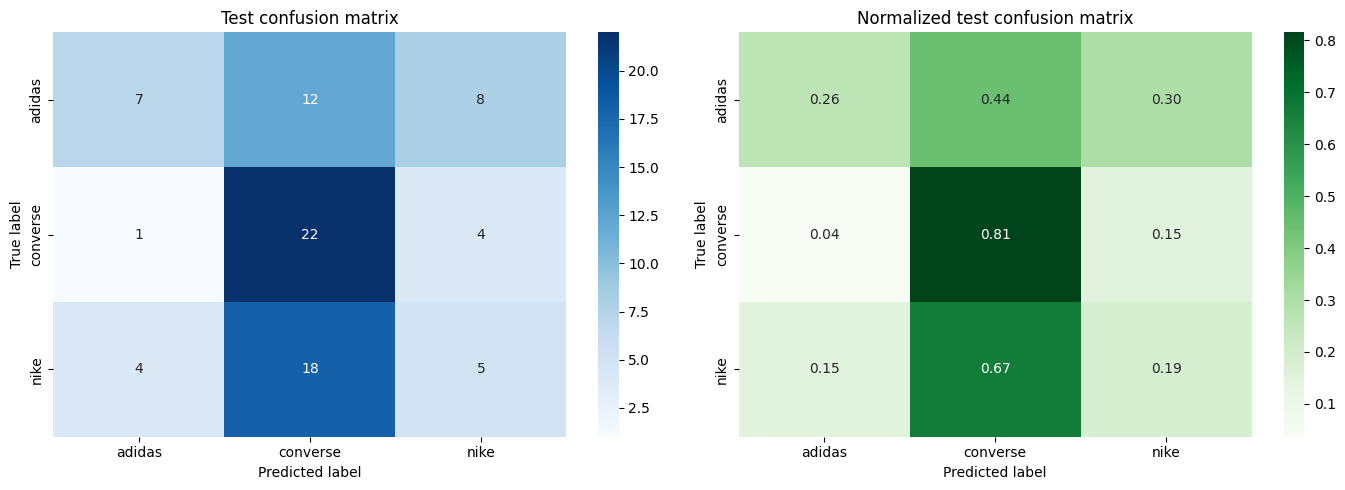

In [3]:
confusion_counts = confusion_matrix(true_labels, predicted_labels, labels=EXPECTED_CLASSES)
confusion_normalized = confusion_matrix(
    true_labels, predicted_labels, labels=EXPECTED_CLASSES, normalize="true"
)

figure, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(confusion_counts, annot=True, fmt="d", cmap="Blues", xticklabels=EXPECTED_CLASSES, yticklabels=EXPECTED_CLASSES, ax=axes[0])
axes[0].set_title("Test confusion matrix")
sns.heatmap(confusion_normalized, annot=True, fmt=".2f", cmap="Greens", xticklabels=EXPECTED_CLASSES, yticklabels=EXPECTED_CLASSES, ax=axes[1])
axes[1].set_title("Normalized test confusion matrix")
for axis in axes:
    axis.set_xlabel("Predicted label")
    axis.set_ylabel("True label")
plt.tight_layout()
plt.show()

## 12. Error and confidence analysis

,image_path,true_label,predicted_label,confidence,probability_adidas,probability_converse,probability_nike,correct
3,C:\my-project\shoe-brand-classifier\modeling\d...,adidas,converse,1.000000,4.776853e-22,1.000000e+00,3.656960e-20,False
19,C:\my-project\shoe-brand-classifier\modeling\d...,adidas,converse,1.000000,1.015056e-11,1.000000e+00,1.130615e-09,False
11,C:\my-project\shoe-brand-classifier\modeling\d...,adidas,converse,1.000000,3.182845e-16,1.000000e+00,1.824670e-10,False
64,C:\my-project\shoe-brand-classifier\modeling\d...,nike,converse,1.000000,4.402056e-21,1.000000e+00,1.606075e-15,False
73,C:\my-project\shoe-brand-classifier\modeling\d...,nike,converse,1.000000,3.609571e-14,1.000000e+00,1.523534e-10,False
55,C:\my-project\shoe-brand-classifier\modeling\d...,nike,converse,1.000000,7.238805e-11,1.000000e+00,1.771158e-09,False
20,C:\my-project\shoe-brand-classifier\modeling\d...,adidas,converse,1.000000,3.498868e-07,9.999996e-01,5.848455e-08,False
57,C:\my-project\shoe-brand-classifier\modeling\d...,nike,converse,1.000000,5.220456e-07,9.999995e-01,8.942112e-09,False
78,C:\my-project\shoe-brand-classifier\modeling\d...,nike,converse,0.999997,9.315018e-11,9.999974e-01,2.577031e-06,False
68,C:\my-project\shoe-brand-classifier\modeling\d...,nike,converse,0.999992,7.933396e-06,9.999917e-01,3.404413e-07,False


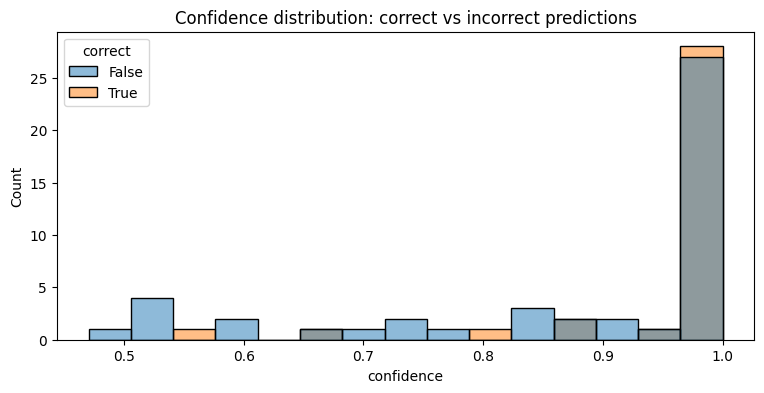

,image_path,true_label,predicted_label,confidence,probability_adidas,probability_converse,probability_nike,correct
1,C:\my-project\shoe-brand-classifier\modeling\d...,adidas,nike,0.470513,0.071897,4.575898e-01,0.470513,False
69,C:\my-project\shoe-brand-classifier\modeling\d...,nike,converse,0.516142,0.016150,5.161421e-01,0.467708,False
4,C:\my-project\shoe-brand-classifier\modeling\d...,adidas,nike,0.528960,0.097412,3.736281e-01,0.528960,False
34,C:\my-project\shoe-brand-classifier\modeling\d...,converse,nike,0.531784,0.075874,3.923415e-01,0.531784,False
37,C:\my-project\shoe-brand-classifier\modeling\d...,converse,adidas,0.537813,0.537813,8.876757e-02,0.373419,False
46,C:\my-project\shoe-brand-classifier\modeling\d...,converse,converse,0.559539,0.259608,5.595386e-01,0.180853,True
23,C:\my-project\shoe-brand-classifier\modeling\d...,adidas,converse,0.581062,0.396938,5.810617e-01,0.022000,False
75,C:\my-project\shoe-brand-classifier\modeling\d...,nike,adidas,0.599435,0.599435,1.284687e-03,0.399281,False
24,C:\my-project\shoe-brand-classifier\modeling\d...,adidas,nike,0.657996,0.341894,1.101744e-04,0.657996,False
18,C:\my-project\shoe-brand-classifier\modeling\d...,adidas,adidas,0.658736,0.658736,1.605762e-11,0.341264,True


In [4]:
misclassifications = predictions[~predictions["correct"]].sort_values("confidence", ascending=False)
display(misclassifications)

figure, axis = plt.subplots(figsize=(9, 4))
sns.histplot(
    data=predictions, x="confidence", hue="correct", bins=15, multiple="layer",
    stat="count", common_norm=False, ax=axis,
)
axis.set_title("Confidence distribution: correct vs incorrect predictions")
plt.show()

display(predictions.nsmallest(10, "confidence"))

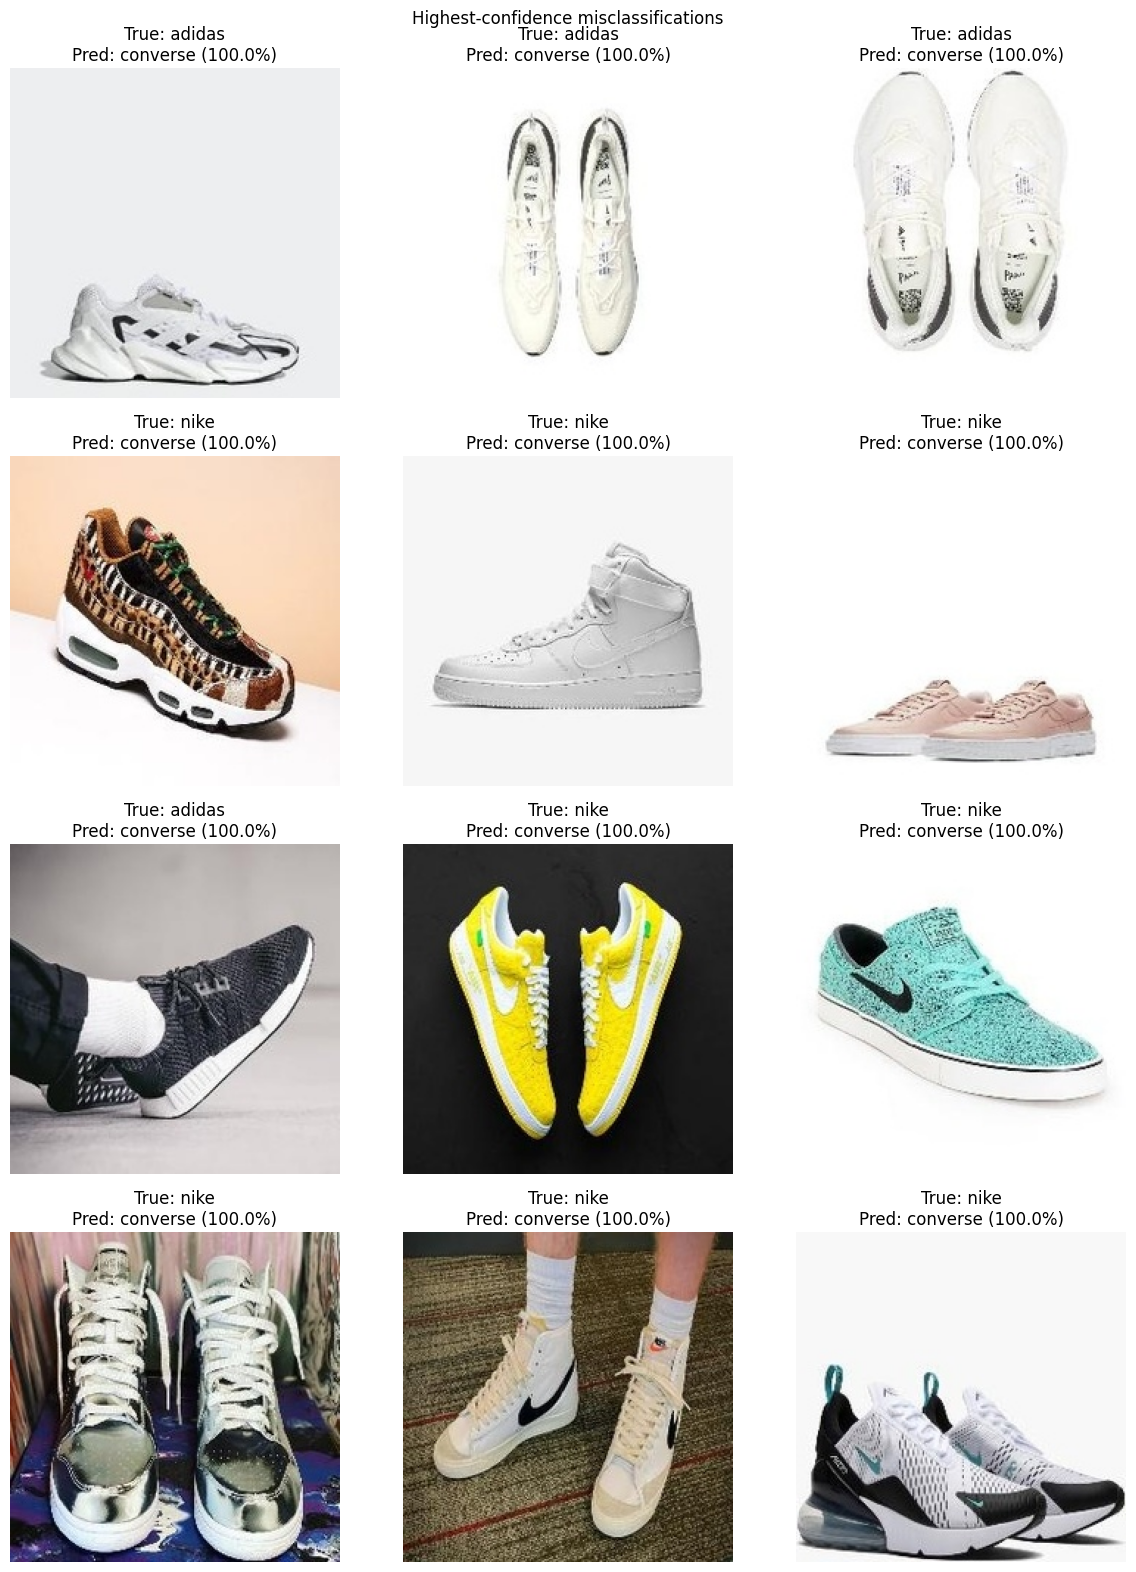

In [5]:
def show_prediction_grid(rows: pd.DataFrame, title: str, max_images: int = 12) -> None:
    rows = rows.head(max_images)
    if rows.empty:
        print(f"No images to display for {title}.")
        return
    columns = 3
    row_count = int(np.ceil(len(rows) / columns))
    figure, axes = plt.subplots(row_count, columns, figsize=(12, 4 * row_count), squeeze=False)
    for axis, (_, row) in zip(axes.flat, rows.iterrows()):
        with Image.open(row["image_path"]) as image:
            axis.imshow(image)
        axis.set_title(
            f"True: {row['true_label']}\nPred: {row['predicted_label']} ({row['confidence']:.1%})"
        )
        axis.axis("off")
    for axis in axes.flat[len(rows):]:
        axis.axis("off")
    figure.suptitle(title)
    plt.tight_layout()
    plt.show()


show_prediction_grid(misclassifications, "Highest-confidence misclassifications")

## 13. Baseline versus final model

In [6]:
baseline_best_model = YOLO(str(BASELINE_BEST_PATH))
baseline_validation_metrics = baseline_best_model.val(
    data=str(DATASET_ROOT), split="val", imgsz=IMAGE_SIZE, batch=BATCH_SIZE, device=DEVICE
)
model_comparison = pd.DataFrame([
    {
        "model": "baseline",
        "validation_top1": float(baseline_validation_metrics.top1),
        "validation_top5": float(baseline_validation_metrics.top5),
        "training_minutes": baseline_duration_seconds / 60,
        "checkpoint": str(BASELINE_BEST_PATH),
    },
    {
        "model": "final_tuned",
        "validation_top1": float(validation_metrics.top1),
        "validation_top5": float(validation_metrics.top5),
        "training_minutes": final_duration_seconds / 60,
        "checkpoint": str(FINAL_BEST_PATH),
    },
])
display(model_comparison)

Ultralytics 8.4.213  Python-3.11.9 torch-2.15.0+cpu CPU (Intel Core i5-10300H 2.50GHz)
YOLO11n-cls summary (fused): 47 layers, 1,529,867 parameters, 0 gradients, 3.2 GFLOPs
train: C:\my-project\shoe-brand-classifier\modeling\datasets\shoe_brands_preprocessed\train... found 579 images in 3/3 classes  
val: C:\my-project\shoe-brand-classifier\modeling\datasets\shoe_brands_preprocessed\val... found 165 images in 3/3 classes  
test: C:\my-project\shoe-brand-classifier\modeling\datasets\shoe_brands_preprocessed\test... found 81 images in 3/3 classes  
val: Fast image access  (ping: 0.1±0.0 ms, read: 70.8±48.3 MB/s, size: 13.2 KB)
val: Scanning C:\my-project\shoe-brand-classifier\modeling\datasets\shoe_brands_preprocessed\val... 165 images, 0 corrupt: 100% ━━━━━━━━━━━━ 165/165  0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 6/6 3.1it/s 2.0s0.4s
                   all      0.921          1
Speed: 0.0ms preprocess, 7.1ms inference, 0.0ms loss, 0.0ms postprocess per image


,model,validation_top1,validation_top5,training_minutes,checkpoint
0,baseline,0.921212,1.0,13.824533,C:\my-project\shoe-brand-classifier\modeling\r...
1,final_tuned,0.624242,1.0,6.788850,C:\my-project\shoe-brand-classifier\modeling\r...


## 14. Save evaluation artifacts

In [7]:
EVALUATION_ROOT.mkdir(parents=True, exist_ok=True)
predictions.to_csv(EVALUATION_ROOT / "test_predictions.csv", index=False)
misclassifications.to_csv(EVALUATION_ROOT / "misclassifications.csv", index=False)
classification_report_frame.to_csv(EVALUATION_ROOT / "classification_report.csv")
pd.DataFrame(confusion_counts, index=EXPECTED_CLASSES, columns=EXPECTED_CLASSES).to_csv(
    EVALUATION_ROOT / "confusion_matrix.csv"
)
model_comparison.to_csv(EVALUATION_ROOT / "model_comparison.csv", index=False)
with (EVALUATION_ROOT / "metrics_summary.json").open("w", encoding="utf-8") as metrics_file:
    json.dump(metrics_summary, metrics_file, indent=2)

experiment_manifest = {
    "model_checkpoint": MODEL_CHECKPOINT,
    "dataset_root": str(DATASET_ROOT),
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "seed": SEED,
    "device": str(DEVICE),
    "ultralytics_version": ultralytics_version,
    "pytorch_version": torch.__version__,
    "best_checkpoint": str(FINAL_BEST_PATH),
    "best_hyperparameters": final_hyperparameters,
}
with (EVALUATION_ROOT / "experiment_manifest.json").open("w", encoding="utf-8") as manifest_file:
    json.dump(experiment_manifest, manifest_file, indent=2, default=str)
print(f"Evaluation artifacts saved to: {EVALUATION_ROOT}")

Evaluation artifacts saved to: C:\my-project\shoe-brand-classifier\modeling\runs\training\evaluation


## 15. Reusable single-image inference

In [8]:
def classify_shoe(image_source: str | Path) -> dict:
    result = best_model.predict(
        source=str(image_source), imgsz=IMAGE_SIZE, device=DEVICE, verbose=False
    )[0]
    if result.probs is None:
        raise RuntimeError("The model returned no classification probabilities.")
    probabilities = result.probs.data.detach().cpu().numpy()
    predicted_index = int(result.probs.top1)
    return {
        "class_name": result.names[predicted_index],
        "confidence": float(result.probs.top1conf.detach().cpu()),
        "probabilities": {
            result.names[index]: float(probability)
            for index, probability in enumerate(probabilities)
        },
    }


sample_image = Path(predictions.iloc[0]["image_path"])
print(classify_shoe(sample_image))

{'class_name': 'adidas', 'confidence': 0.9706571102142334, 'probabilities': {'adidas': 0.9706571102142334, 'converse': 6.454446894489652e-13, 'nike': 0.02934293821454048}}


## 16. Export the best model to ONNX

In [9]:
if EXPORT_ONNX:
    exported_model_path = best_model.export(
        format="onnx",
        imgsz=IMAGE_SIZE,
        batch=1,
        dynamic=False,
        simplify=True,
        device=DEVICE,
    )
    print(f"Exported ONNX model: {exported_model_path}")

Ultralytics 8.4.213  Python-3.11.9 torch-2.15.0+cpu CPU (Intel Core i5-10300H 2.50GHz)
 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n-cls summary (fused): 47 layers, 1,529,867 parameters, 0 gradients, 0.4 GFLOPs

PyTorch: starting from 'C:\my-project\shoe-brand-classifier\modeling\runs\training\final\weights\best.pt' with input shape (1, 3, 224, 224) BCHW and output shape(s) (1, 3) (3.0 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/7.9 MB ? eta -:--:--
   ---------------------------------------- 0.1/7.9 MB 3.4 MB/s eta 0:00:03
   - -------------------------------------- 0.2/7.9 MB 2.6 MB/s eta 0:00:03
   - -------------------------------------- 0.3/7.9 MB 2.7 MB/s eta 0:00

## 17. Optional resume training

In [ ]:
# Resume training is intentionally unavailable because only best full models are retained.